# Import all necessary libraries

In [2]:
from pathlib import Path
import warnings
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    f1_score,
    precision_score,
    recall_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import clone

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
warnings.filterwarnings("default")

RANDOM_STATE = 42
DATA_PATH = Path("../data/raw/credit_risk_dataset.csv")
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "loan_status"


# **After data preprocessing Final DATA**

In [3]:
df=pd.read_csv("FInal_data.csv")
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


###  Feature leakage decision

In [4]:
EXCLUDE_FEATURES = [TARGET]

X = df.drop(columns=EXCLUDE_FEATURES).copy()
y = df[TARGET].copy()

print("Features used:", X.columns.tolist())
print("X shape:", X.shape)
print("y shape:", y.shape)

Features used: ['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']
X shape: (32416, 11)
y shape: (32416,)


#  Train-Test Split
- We split the data into a training part and a testing part.
- The model learns from the training part only.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nTraining class proportions:")
display((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTest class proportions:")
display((y_test.value_counts(normalize=True) * 100).round(2))

Train shape: (25932, 11)
Test shape: (6484, 11)

Training class proportions:


loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64


Test class proportions:


loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64

# Handle Class Imbalance
- Very few people actually default in this data.
- If we ignore this, the model may just favor the majority class.
- We give more importance to the minority class during training.
- This helps the model actually learn to spot defaulters.

In [6]:
# This is for xboost 
#0 -> no loan (most)
#1 -> yes loan

neg, pos = np.bincount(y_train)
scale_weigths = neg/pos

## Build leakage-safe preprocessing

In [7]:
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

Numerical features: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Categorical features: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


C:\Users\jaman\AppData\Local\Temp\ipykernel_17772\692802851.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


# *Baseline Model (NO tune,NO cv)*

In [9]:
baseline_model=Pipeline(steps=[
    ("preprocessor",preprocessor),
    ("Classification",LogisticRegression())
])
baseline_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('Classification', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedc

In [10]:
from sklearn.metrics import accuracy_score

In [16]:
y_pred=baseline_model.predict(X_test)
print(accuracy_score(y_test,y_pred))
print(precision_score(y_test,y_pred))
print(recall_score(y_test,y_pred))
confusion_matrix(y_test,y_pred)

0.8690623072177668
0.7727708533077661
0.5684062059238364


array([[4829,  237],
       [ 612,  806]])

## 8. Compare baseline models

In [17]:
# from sklearn.ensemble import HistGradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
}

# XGBoost is optional; install with: pip install xgboost
try:
    from xgboost import XGBClassifier

    models["XGBoost"] = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
except ImportError:
    print("XGBoost is not installed. Run: pip install xgboost")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

comparison_results = []

for name, classifier in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    comparison_results.append({
        "model": name,
        "roc_auc_mean": scores["test_roc_auc"].mean(),
        "pr_auc_mean": scores["test_pr_auc"].mean(),
        "precision_mean": scores["test_precision"].mean(),
        "recall_mean": scores["test_recall"].mean(),
        "f1_mean": scores["test_f1"].mean()
    })

comparison_df = pd.DataFrame(comparison_results).sort_values(
    "pr_auc_mean", ascending=False
)

display(comparison_df.round(4))

,model,roc_auc_mean,pr_auc_mean,precision_mean,recall_mean,f1_mean
2,XGBoost,0.9456,0.8998,0.9721,0.7249,0.8305
1,Random Forest,0.9310,0.8819,0.8699,0.7485,0.8047
0,Logistic Regression,0.8708,0.7167,0.5468,0.7792,0.6426


Choose the leading model based on cross-validation results and the project's risk objective, not on test-set performance. For an imbalanced target, PR-AUC is useful, but also consider recall, precision, calibration, and the consequences of different errors.

## 9. Tune XGBoost

In [19]:
if "XGBoost" not in models:
    raise ImportError("Install xgboost first: pip install xgboost")

xgb_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", models["XGBoost"])
])

param_distributions = {
    "classifier__n_estimators": [200, 300, 500],
    "classifier__max_depth": [3, 4, 5, 6],
    "classifier__learning_rate": [0.02, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 1.0],
    "classifier__min_child_weight": [1, 3, 5],
    "classifier__reg_lambda": [1, 3, 5]
}

search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1,
    refit=True
)

search.fit(X_train, y_train)

print("Best parameters:")
print(search.best_params_)
print("Best CV PR-AUC:", round(search.best_score_, 4))
print()

best_model = search.best_estimator_

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best parameters:
{'classifier__subsample': 1.0, 'classifier__reg_lambda': 3, 'classifier__n_estimators': 500, 'classifier__min_child_weight': 3, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.1, 'classifier__colsample_bytree': 0.7}
Best CV PR-AUC: 0.9059




## 10. Select a threshold using validation data

The following creates a validation split from the training data. It uses the tuned configuration and selects a threshold by validation F1. For a stricter workflow, tune hyperparameters within `X_fit` only and use `X_val` exclusively for threshold selection.

In [20]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=RANDOM_STATE
)

validation_model = clone(best_model) 
validation_model.fit(X_fit, y_fit) 

y_prob_val = validation_model.predict_proba(X_val)[:, 1] 

precision, recall, thresholds = precision_recall_curve(y_val, y_prob_val) 

f1_values = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)
# f1_values = 2 * (precision-recall) / (precision + recall + 1e-9)

best_idx = int(np.argmax(f1_values))
selected_threshold = float(thresholds[best_idx])

print("Selected threshold:", round(selected_threshold, 4))
print("Validation precision:", round(precision[best_idx], 4))
print("Validation recall:", round(recall[best_idx], 4))
print("Validation F1:", round(f1_values[best_idx], 4))

Selected threshold: 0.5823
Validation precision: 0.9834
Validation recall: 0.7293
Validation F1: 0.8375


The best F1 threshold is a baseline, not automatically the right business decision. A real application should select a threshold using validated costs, fairness considerations, and a documented policy.

## 11. Fit final model and evaluate on test set

ROC-AUC: 0.9524
PR-AUC: 0.9105

Classification report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.96      5066
           1       0.98      0.73      0.84      1418

    accuracy                           0.94      6484
   macro avg       0.95      0.86      0.90      6484
weighted avg       0.94      0.94      0.93      6484



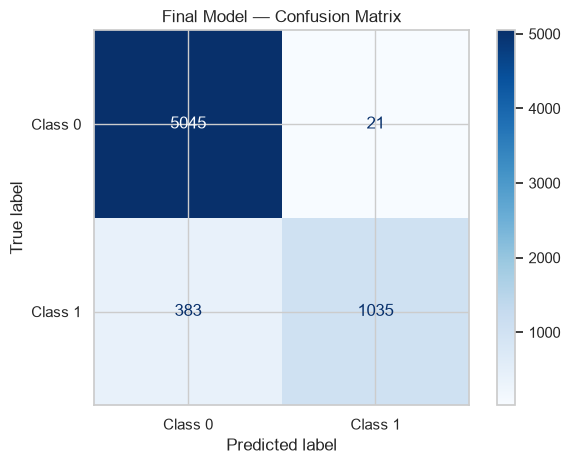

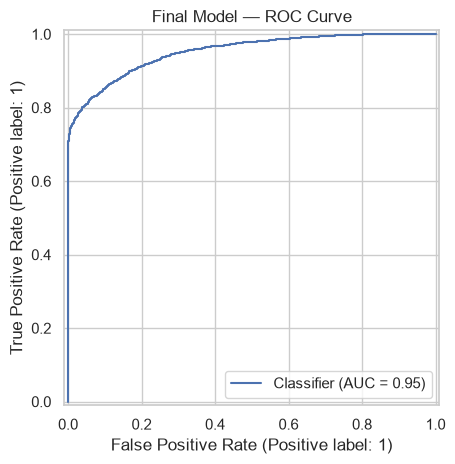

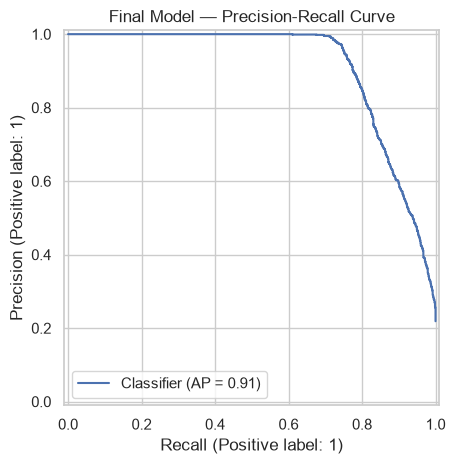

In [21]:
final_model = clone(best_model)
final_model.fit(X_train, y_train)

y_prob_test = final_model.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= selected_threshold).astype(int)

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_test), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob_test), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred_test, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test,
    display_labels=["Class 0", "Class 1"],
    cmap="Blues"
)
plt.title("Final Model — Confusion Matrix")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, y_prob_test)
plt.title("Final Model — ROC Curve")
plt.tight_layout()
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, y_prob_test)
plt.title("Final Model — Precision-Recall Curve")
plt.tight_layout()
plt.show()

##  SHAP Interpretation — Global & Local
- SHAP helps us understand why the model makes a decision.
- It is a way of explaining a "black box" model

In [27]:
import shap

In [43]:

XGB_shap = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", models["XGBoost"])
])
XGB_shap.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolum

In [46]:


#2. Get the Trained XGBoost classifier model out of the pipeline.
xgb_classifier = XGB_shap.named_steps['classifier']

#3. Transform X_test using the same preprocessing used for training.
X_test_transformed = XGB_shap.named_steps['preprocessor'].transform(X_test)


#4. Get feature names after one-hot enocding , so plots are readable
feature_names = XGB_shap.named_steps['preprocessor'].get_feature_names_out()

#5. Convert to a dataframe for cleaner SHAP plots
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

#6. Create SHAP explainer built for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)

shap_values = explainer(X_test_df)

print(shap_values.values.shape)

(6484, 26)


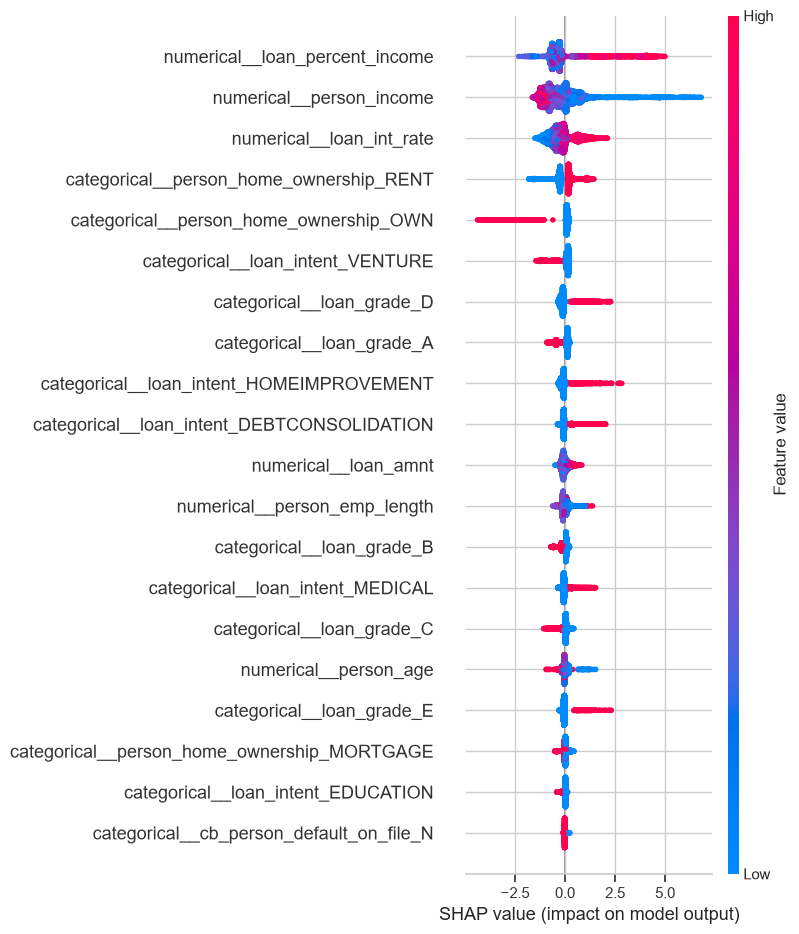

In [47]:
shap.summary_plot(shap_values,X_test_df)

# Error analysis
##  Analyzing False Positives & False Negatives
- The model will not be perfect.
- False positives are safe people wrongly marked risky.
- False negatives are risky people wrongly marked safe.
- We study these cases to understand where the model struggles.


In [26]:
error_analysis = X_test.copy()
error_analysis["actual"] = y_test
error_analysis["predicted"] = y_pred_test
error_analysis["predicted_probability"] = y_prob_test

errors = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
].copy()


#Identify False Positive : Model Predicted 1, but the actual was 0
false_positive = error_analysis[(error_analysis['actual']== 0) & (error_analysis['predicted']== 1)]

#Identify False Negative : Model Predicted 0, but the actual was 1
false_negative = error_analysis[(error_analysis['actual']== 1) & (error_analysis['predicted']== 0)]

print(f"False Positive : {len(false_positive)}")
print(f"False Negative : {len(false_negative)}")
print("Test rows:", len(X_test))
print("Incorrect predictions:", len(errors))
print("Error rate (%):", round(len(errors) / len(X_test) * 100, 2))
print()
display(errors.head(10))

False Positive : 21
False Negative : 383
Test rows: 6484
Incorrect predictions: 404
Error rate (%): 6.23



,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted,predicted_probability
26854,30,108000,MORTGAGE,0.0,DEBTCONSOLIDATION,B,4925,NaN,0.05,N,9,1,0,0.048742
10819,22,36000,RENT,4.0,PERSONAL,B,10000,11.36,0.28,N,2,1,0,0.140539
28093,28,41000,RENT,11.0,VENTURE,E,4000,18.64,0.10,Y,5,1,0,0.229249
31205,37,78000,MORTGAGE,0.0,PERSONAL,B,5600,10.74,0.07,N,12,1,0,0.226095
7843,26,36000,RENT,NaN,MEDICAL,C,7000,13.98,0.19,Y,2,1,0,0.094944
3127,22,29554,MORTGAGE,NaN,DEBTCONSOLIDATION,A,5775,5.42,0.20,N,3,1,0,0.084315
20439,28,88000,RENT,3.0,PERSONAL,B,10000,10.65,0.11,N,9,1,0,0.055662
15495,23,56525,RENT,1.0,MEDICAL,B,15000,11.48,0.23,N,4,1,0,0.299667
32083,40,52479,RENT,17.0,HOMEIMPROVEMENT,D,6600,14.54,0.13,N,17,1,0,0.436346
27886,28,33000,RENT,12.0,PERSONAL,C,8000,14.65,0.24,N,9,1,0,0.279908
